# Hinglish Sarcasm Detector — Training and Evaluation

**Course:** Natural Language Processing (ICT, Semester 7) · Pandit Deendayal Energy University, Gandhinagar
**Team:** Khushi Panchotiya (23BIT112) · Grishma Makwana (23BIT108)

**Task:** binary text classification of code-mixed Hindi–English (Hinglish) comments as **Sarcastic** or **Sincere**.

This notebook walks through everything we did, in order, and shows the real results:

1. Dataset and cleaning
2. Sarcasm-aware preprocessing
3. Train / validation / test split
4. Baseline: TF-IDF + Logistic Regression (trained live in this notebook)
5. Transformer fine-tuning: MuRIL, XLM-RoBERTa, HingBERT (the training code is shown; training itself ran on a Colab GPU)
6. Evaluation of every model on the same held-out test set
7. Model comparison with confidence intervals
8. Error analysis and LIME explanations
9. Conclusions and limitations

All code lives in the project's `src/` folder; this notebook imports and displays it.

### Setup (Google Colab)
Upload `hinglish_colab_files.zip` to the Colab file panel (left sidebar), then run the next two cells. Running locally? Skip the unzip cell.

In [1]:
# Colab only: unzip the project files and install the two extra libraries
import os, sys, subprocess
if os.path.exists("hinglish_colab_files.zip") and not os.path.exists("src"):
    subprocess.run(["unzip", "-q", "hinglish_colab_files.zip"], check=True)
try:
    import emoji, lime  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "emoji", "lime"], check=True)
print("files:", sorted(os.listdir(".")))

files: ['Hinglish_Sarcasm_Detector_Report.ipynb', 'hinglish_sarcasm_complete_pipeline.ipynb']


In [2]:
import os, sys, json, warnings, inspect
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

from src.config import (RAW_CSV, PROCESSED, MODELS, REPORTS, SEED, LABELS, LABEL2ID,
                        ID2LABEL, TRANSFORMERS)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)
print("Project root:", ROOT)

Project root: /Users/khushi/Desktop/Projects/Hinglish Sarcasm detector


## 1. Dataset

We use the public **Hinglish Sarcasm Detection Dataset** (Jain & Nagulapalli, 2025;
`github.com/mananjen/hinglish_sarcasm_dataset`, file `human_labelled_features.csv`).
The target is the `human_labelled` column. The dataset also has an `ai_labelled` column, which we do **not** use as the target.

> The source repository has no license file. Check permitted use before redistributing the data.

In [3]:
raw = pd.read_csv(RAW_CSV, encoding="utf-8-sig")
print("Raw shape:", raw.shape)
display(raw.head())
display(raw["human_labelled"].value_counts().to_frame("count"))

Raw shape: (8885, 5)


,comment,human_labelled,ai_labelled,emoji_present,hindi_pct
0,Lo or kro Rahul Gandhi face_with_tears_of_joy cross_mark,sarcastic,sarcastic,yes,19.05
1,eesko krte time kitno ne condom nhi lagaya,non-sarcastic,sarcastic,no,78.57
2,"kaam kam, dialogues zyada",sarcastic,sarcastic,no,57.14
3,sudhanshu trivedi ke samne koi bolsakta hai kyaa..aeeeeeeeeee face_with_tears_of_joy,non-sarcastic,sarcastic,yes,30.56
4,nujhe to rona a raha hai ab bas kar bhenji varna main komma main chalah jauga,non-sarcastic,sarcastic,no,100.00


,count
human_labelled,
non-sarcastic,4768
sarcastic,3737
non_sarcastic,377
error,3


### 1.1 Cleaning
Steps (code in `src/prepare_data.py`):
- map label spellings (`non-sarcastic`, `non_sarcastic`) to **Sincere**, `sarcastic` to **Sarcastic**; drop rows with an invalid label (`error`)
- find texts that appear several times with **conflicting** labels and drop all of them
- remove exact duplicates (after lower-casing and whitespace normalisation) so the same comment cannot appear in both train and test

In [4]:
audit = json.loads((REPORTS / "data_audit.json").read_text())
display(pd.Series(audit).to_frame("value"))

,value
raw_rows,8885
invalid_label_rows,3
conflicting_duplicate_texts,24
final_rows,8464
class_counts,"{'Sincere': 4819, 'Sarcastic': 3645}"
split_sizes,"{'train': 6771, 'validation': 846, 'test': 847}"


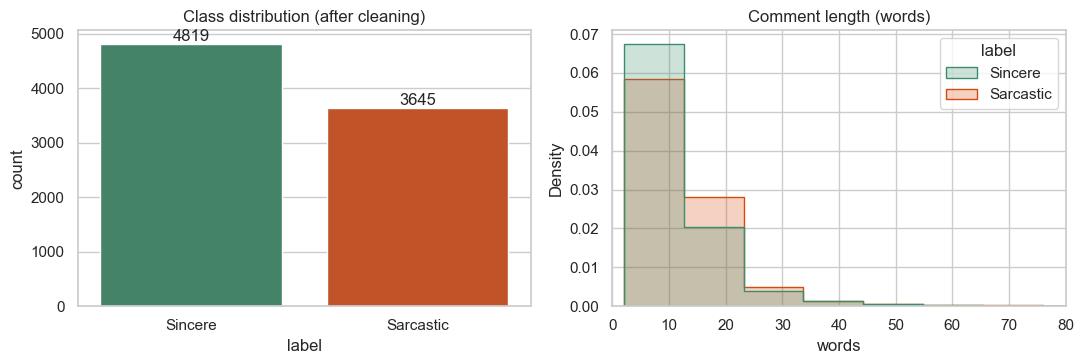

Sarcastic share: 43.1%  (mild imbalance, so macro-F1 is our main metric)


In [5]:
clean = pd.read_csv(PROCESSED / "cleaned.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = ["Sincere", "Sarcastic"]
sns.countplot(data=clean, x="label", order=order, palette=["#3b8d6b", "#d9480f"], ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom")
ax[0].set_title("Class distribution (after cleaning)")
clean["words"] = clean["raw_text"].str.split().str.len()
sns.histplot(data=clean, x="words", hue="label", bins=40, element="step", stat="density",
             common_norm=False, hue_order=order, palette=["#3b8d6b", "#d9480f"], ax=ax[1])
ax[1].set_xlim(0, 80); ax[1].set_title("Comment length (words)")
plt.tight_layout(); plt.show()
print(f"Sarcastic share: {(clean.label == 'Sarcastic').mean():.1%}  (mild imbalance, so macro-F1 is our main metric)")

## 2. Preprocessing

Design choices specific to sarcasm (code in `src/preprocess.py`):
- **keep emojis and punctuation**, because `!!!` and `...` carry tone (emojis are converted to words so the tokenizer can use them)
- **keep stop words**, since small words like *bilkul* and *kya* shape sarcastic meaning
- collapse stretched characters (*waaaah* → *waah*)

In [6]:
from src import preprocess
print(inspect.getsource(preprocess))

"""Sarcasm-aware text normalisation.

Design choices (see docs/overview): keep emojis and punctuation, keep stop words,
collapse stretched characters, leave casing information to the model tokenizer.
"""
import re
import unicodedata

import emoji

_STRETCH = re.compile(r"(.)\1{2,}")          # waaaah -> waah
_PUNCT_RUN = re.compile(r"([!?.])\1{3,}")     # !!!!!! -> !!!
_URL = re.compile(r"https?://\S+|www\.\S+")
_MENTION = re.compile(r"@\w+")
_SPACES = re.compile(r"\s+")


def normalize(text: str) -> str:
    text = unicodedata.normalize("NFKC", str(text))
    text = _URL.sub(" ", text)
    text = _MENTION.sub("@user", text)
    # real emoji characters -> words (the dataset already stores emojis as words)
    text = emoji.demojize(text, delimiters=(" ", " "))
    text = _STRETCH.sub(r"\1\1", text)
    text = _PUNCT_RUN.sub(r"\1\1\1", text)
    return _SPACES.sub(" ", text).strip()


def dedup_key(text: str) -> str:
    return _SPACES.sub(" ", unicodedata.normalize("NFKC", str(text)).lo

In [7]:
examples = ["waaaaah kya baat haiii!!!!!!", "Great 😂😂 another Monday meeting @boss https://x.co/abc",
            "wah kya baat hai, bilkul time pe aaye"]
display(pd.DataFrame({"raw": examples, "normalized": [preprocess.normalize(e) for e in examples]}))

,raw,normalized
0,waaaaah kya baat haiii!!!!!!,waah kya baat haii!!
1,Great 😂😂 another Monday meeting @boss https://x.co/abc,Great face_with_tears_of_joy face_with_tears_of_joy another Monday meeting @user
2,"wah kya baat hai, bilkul time pe aaye","wah kya baat hai, bilkul time pe aaye"


## 3. Train / validation / test split

Stratified 80 / 10 / 10 split with a fixed seed (42), so every class has the same proportion in each part.
The **validation set** is used for model selection (early stopping, choosing the best epoch). The **test set** is used once, for final reporting.

In [8]:
train = pd.read_csv(PROCESSED / "train.csv")
val = pd.read_csv(PROCESSED / "validation.csv")
test = pd.read_csv(PROCESSED / "test.csv")

rows = []
for name, part in [("train", train), ("validation", val), ("test", test)]:
    vc = part["label"].value_counts()
    rows.append({"split": name, "rows": len(part), "Sincere": vc["Sincere"], "Sarcastic": vc["Sarcastic"],
                 "Sarcastic %": round(100 * vc["Sarcastic"] / len(part), 1)})
display(pd.DataFrame(rows).set_index("split"))

keys = lambda d: set(d["raw_text"].str.lower().str.split().str.join(" "))
assert keys(train).isdisjoint(keys(val)) and keys(train).isdisjoint(keys(test)) and keys(val).isdisjoint(keys(test))
print("Check passed: no text appears in more than one split.")

,rows,Sincere,Sarcastic,Sarcastic %
split,,,,
train,6771,3855,2916,43.1
validation,846,482,364,43.0
test,847,482,365,43.1


Check passed: no text appears in more than one split.


## 4. Baseline: TF-IDF + Logistic Regression

A classical reference. Word 1–2-grams and character 2–5-grams are combined as TF-IDF features and fed to a class-balanced Logistic Regression.
It treats words independently, so it cannot model the *mismatch* between praise words and a negative situation that defines sarcasm. This is why we expect transformers to do better.

In [9]:
from src import train_baseline
print(inspect.getsource(train_baseline.build_pipeline))

def build_pipeline() -> Pipeline:
    return Pipeline([
        ("features", FeatureUnion([
            ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2,
                                     sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")),
            ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                                     sublinear_tf=True)),
        ])),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced",
                                          C=2.0, random_state=SEED)),
    ])



=== Majority class (test) ===
Accuracy: 0.5691   Macro-F1: 0.3627
              precision    recall  f1-score   support

     Sincere      0.569     1.000     0.725       482
   Sarcastic      0.000     0.000     0.000       365

    accuracy                          0.569       847
   macro avg      0.285     0.500     0.363       847
weighted avg      0.324     0.569     0.413       847



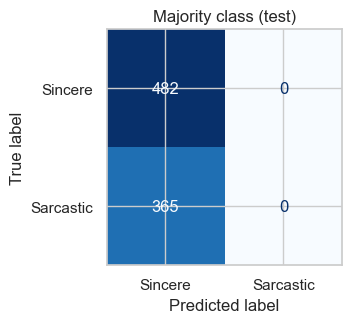

In [10]:
%matplotlib inline
def show_eval(y_true, y_pred, title):
    print(f"=== {title} ===")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}   Macro-F1: {f1_score(y_true, y_pred, average='macro'):.4f}")
    print(classification_report(y_true, y_pred, labels=LABELS, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(3.8, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, values_format="d", cmap="Blues", colorbar=False)
    ax.set_title(title); plt.tight_layout(); plt.show()

# Majority-class reference (always predicts the most common class)
maj = train["label"].mode()[0]
show_eval(test["label"], [maj] * len(test), "Majority class (test)")

=== TF-IDF + LR (validation) ===
Accuracy: 0.6537   Macro-F1: 0.6501
              precision    recall  f1-score   support

     Sincere      0.710     0.662     0.685       482
   Sarcastic      0.589     0.643     0.615       364

    accuracy                          0.654       846
   macro avg      0.650     0.652     0.650       846
weighted avg      0.658     0.654     0.655       846



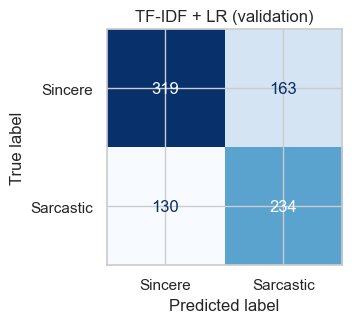

=== TF-IDF + LR (test) ===
Accuracy: 0.6612   Macro-F1: 0.6592
              precision    recall  f1-score   support

     Sincere      0.727     0.647     0.685       482
   Sarcastic      0.593     0.679     0.633       365

    accuracy                          0.661       847
   macro avg      0.660     0.663     0.659       847
weighted avg      0.670     0.661     0.663       847



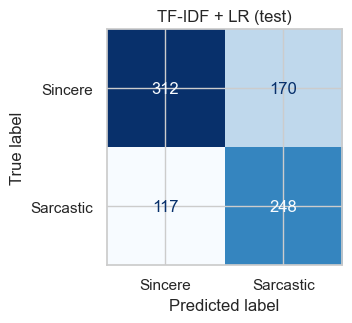

In [11]:
baseline = train_baseline.build_pipeline().fit(train["text"], train["label"])
show_eval(val["label"], baseline.predict(val["text"]), "TF-IDF + LR (validation)")
tfidf_pred = baseline.predict(test["text"])
show_eval(test["label"], tfidf_pred, "TF-IDF + LR (test)")

## 5. Transformer fine-tuning

We fine-tune three pretrained transformers for sequence classification, using identical data splits and hyperparameters so the comparison is fair.

| Model | Hugging Face checkpoint | Why |
|---|---|---|
| MuRIL | `google/muril-base-cased` | pretrained on Indian languages, including transliterated (Roman-script) text |
| XLM-RoBERTa | `xlm-roberta-base` | strong multilingual model, a fair comparison point |
| HingBERT | `l3cube-pune/hing-bert` | pretrained specifically on Hinglish |

**Hyperparameters** (identical for all): max 5 epochs, learning rate 2e-5, batch size 16, max length 128 tokens, weight decay 0.01, 10% linear warm-up, mixed precision on GPU, seed 42.
After each epoch we evaluate on the **validation** set; training stops early after 2 epochs without improvement, and the epoch with the best validation macro-F1 is kept.
Training ran on a free Colab GPU (the code below is `src/finetune.py`, which we executed there with `python -m src.finetune --model <name>`).

In [12]:
print((ROOT / "src" / "finetune.py").read_text())

"""Fine-tune a transformer on the project splits.

Run on a GPU (Colab/Kaggle):
    python -m src.finetune --model muril
    python -m src.finetune --model xlmr
    python -m src.finetune --model hingbert
Outputs: models/<name>/ (weights) and reports/metrics_<name>.json
"""
import argparse
import time

import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, EarlyStoppingCallback, Trainer,
                          TrainingArguments, set_seed)

from src.config import ID2LABEL, LABEL2ID, MODELS, PROCESSED, SEED, TRANSFORMERS
from src.metrics import evaluate


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", choices=TRANSFORMERS, required=True)
    ap.add_argument("--epochs", type=int, default=5)
    ap.add_argument("--lr", type=float, default=2e-5)
    ap.a

## 6. Evaluating the trained models on the test set

The fine-tuned weights (about 2.4 GB in total) stay on our machine. After training, we ran each model once on the 847 held-out test comments and saved its predictions to `reports/test_predictions.csv` (`python -m src.save_test_predictions`). Every table and chart below is computed from those predictions, so anyone can check the metrics without the weights.

> The predictions were produced on CPU in full precision, while the training run evaluated on GPU with mixed precision, so macro-F1 can differ by about 0.001 between the two (compared below).

In [13]:
saved_preds = pd.read_csv(REPORTS / "test_predictions.csv")
assert (saved_preds["raw_text"].values == test["raw_text"].values).all(), "prediction rows must match test.csv"

preds = {"Majority class": np.array([maj] * len(test)), "TF-IDF + LR": np.asarray(tfidf_pred)}
names = {"muril": "MuRIL", "xlmr": "XLM-RoBERTa", "hingbert": "HingBERT"}
for key, nice in names.items():
    preds[nice] = saved_preds[key].values
    saved = json.loads((REPORTS / f"metrics_{key}.json").read_text())["macro_f1"]
    now = f1_score(test["label"], preds[nice], average="macro")
    print(f"{nice:12s} macro-F1 from saved predictions {now:.4f} | logged at end of GPU training {saved:.4f}")
print("TF-IDF here is retrained live above; saved copy agrees:",
      round(f1_score(test['label'], saved_preds['tfidf_lr'], average='macro'), 4))

MuRIL        macro-F1 from saved predictions 0.6643 | logged at end of GPU training 0.6654
XLM-RoBERTa  macro-F1 from saved predictions 0.6459 | logged at end of GPU training 0.6459
HingBERT     macro-F1 from saved predictions 0.6939 | logged at end of GPU training 0.6928
TF-IDF here is retrained live above; saved copy agrees: 0.6592


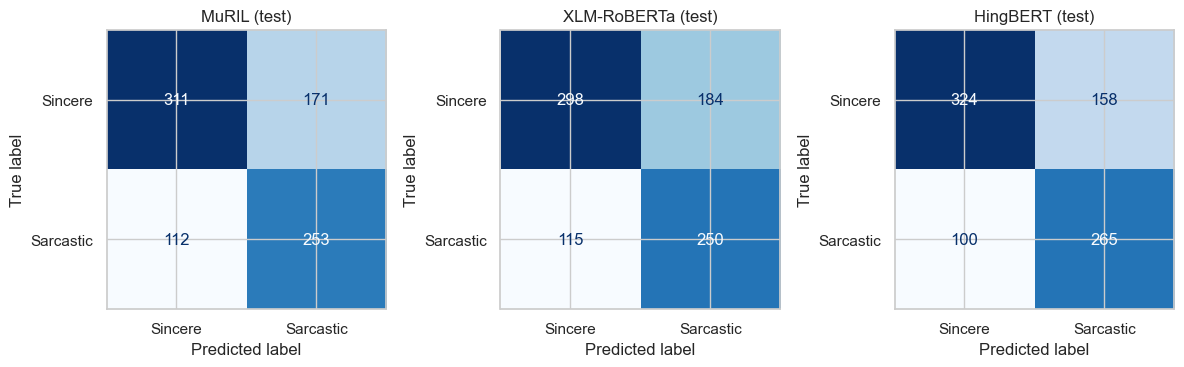


--- MuRIL ---
              precision    recall  f1-score   support

     Sincere      0.735     0.645     0.687       482
   Sarcastic      0.597     0.693     0.641       365

    accuracy                          0.666       847
   macro avg      0.666     0.669     0.664       847
weighted avg      0.676     0.666     0.667       847


--- XLM-RoBERTa ---
              precision    recall  f1-score   support

     Sincere      0.722     0.618     0.666       482
   Sarcastic      0.576     0.685     0.626       365

    accuracy                          0.647       847
   macro avg      0.649     0.652     0.646       847
weighted avg      0.659     0.647     0.649       847


--- HingBERT ---
              precision    recall  f1-score   support

     Sincere      0.764     0.672     0.715       482
   Sarcastic      0.626     0.726     0.673       365

    accuracy                          0.695       847
   macro avg      0.695     0.699     0.694       847
weighted avg      0.

In [14]:
y_test = test["label"].values
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, nice in zip(axes, names.values()):
    cm = confusion_matrix(y_test, preds[nice], labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, values_format="d", cmap="Blues", colorbar=False)
    ax.set_title(f"{nice} (test)")
plt.tight_layout(); plt.show()
for nice in names.values():
    print(f"\n--- {nice} ---")
    print(classification_report(y_test, preds[nice], labels=LABELS, digits=3))

## 7. Model comparison

In [15]:
def summary(pred):
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    return {"Accuracy": accuracy_score(y_test, pred), "Macro precision": p, "Macro recall": r, "Macro-F1": f}

table = pd.DataFrame({k: summary(v) for k, v in preds.items()}).T
per_class = pd.DataFrame({k: dict(zip([f"F1 {l}" for l in LABELS],
                          precision_recall_fscore_support(y_test, v, labels=LABELS, zero_division=0)[2]))
                          for k, v in preds.items()}).T
display(pd.concat([table, per_class], axis=1).round(3).sort_values("Macro-F1", ascending=False))

,Accuracy,Macro precision,Macro recall,Macro-F1,F1 Sincere,F1 Sarcastic
HingBERT,0.695,0.695,0.699,0.694,0.715,0.673
MuRIL,0.666,0.666,0.669,0.664,0.687,0.641
TF-IDF + LR,0.661,0.660,0.663,0.659,0.685,0.633
XLM-RoBERTa,0.647,0.649,0.652,0.646,0.666,0.626
Majority class,0.569,0.285,0.500,0.363,0.725,0.000


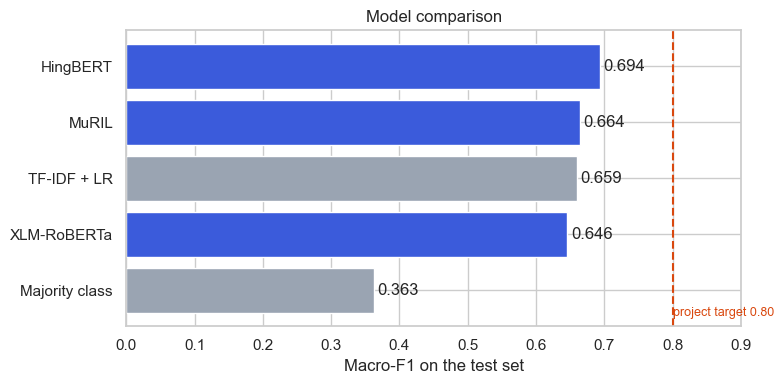

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
order = table["Macro-F1"].sort_values().index
bars = ax.barh(order, table.loc[order, "Macro-F1"], color=["#9aa4b2" if o in ("Majority class", "TF-IDF + LR") else "#3b5bdb" for o in order])
for b in bars:
    ax.text(b.get_width() + 0.005, b.get_y() + b.get_height() / 2, f"{b.get_width():.3f}", va="center")
ax.axvline(0.80, color="#d9480f", ls="--"); ax.text(0.801, -0.45, "project target 0.80", color="#d9480f", fontsize=9)
ax.set_xlim(0, 0.9); ax.set_xlabel("Macro-F1 on the test set"); ax.set_title("Model comparison")
plt.tight_layout(); plt.show()

### 7.1 How reliable are these differences?

The test set has only 847 comments, so small gaps can be luck. We use a **bootstrap**: resample the test set 1,000 times and recompute macro-F1 to get 95% confidence intervals, plus a paired comparison of HingBERT against the TF-IDF baseline on the same resamples.

In [17]:
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(y_test), size=(1000, len(y_test)))
boot = {k: np.array([f1_score(y_test[i], v[i], average="macro") for i in idx]) for k, v in preds.items()}
ci = pd.DataFrame({k: {"Macro-F1": f1_score(y_test, preds[k], average="macro"),
                       "95% CI low": np.percentile(b, 2.5), "95% CI high": np.percentile(b, 97.5)}
                   for k, b in boot.items()}).T
display(ci.round(3).sort_values("Macro-F1", ascending=False))

for nice in ["HingBERT", "MuRIL", "XLM-RoBERTa"]:
    d = boot[nice] - boot["TF-IDF + LR"]
    print(f"{nice:12s} minus TF-IDF: mean {d.mean():+.3f}, 95% CI [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}], "
          f"better in {(d > 0).mean():.0%} of resamples")

,Macro-F1,95% CI low,95% CI high
HingBERT,0.694,0.661,0.726
MuRIL,0.664,0.630,0.698
TF-IDF + LR,0.659,0.624,0.691
XLM-RoBERTa,0.646,0.613,0.677
Majority class,0.363,0.349,0.375


HingBERT     minus TF-IDF: mean +0.035, 95% CI [+0.004, +0.067], better in 99% of resamples
MuRIL        minus TF-IDF: mean +0.005, 95% CI [-0.027, +0.038], better in 63% of resamples
XLM-RoBERTa  minus TF-IDF: mean -0.013, 95% CI [-0.047, +0.019], better in 22% of resamples


## 8. Error analysis (HingBERT, best model)

We sampled **30 wrong predictions** from the test set (HingBERT made 259 errors in total) and read each one to find patterns.

Total HingBERT errors on test: 259 of 847 (30.6%)
predicted  Sarcastic  Sincere
true                         
Sarcastic          0      100
Sincere          159        0


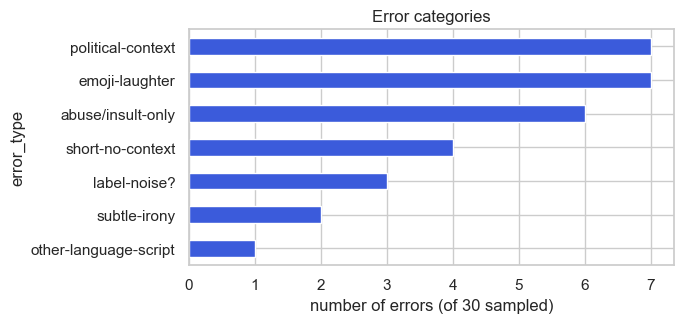

In [18]:
errs_all = pd.read_csv(REPORTS / "errors_hingbert.csv")
print(f"Total HingBERT errors on test: {len(errs_all)} of {len(test)} ({len(errs_all)/len(test):.1%})")
print(pd.crosstab(errs_all["label"], errs_all["prediction"], rownames=["true"], colnames=["predicted"]))

ea = pd.read_csv(REPORTS / "error_analysis_hingbert.csv")
counts = ea["error_type"].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.4))
counts.sort_values().plot.barh(color="#3b5bdb", ax=ax)
ax.set_xlabel("number of errors (of 30 sampled)"); ax.set_title("Error categories")
plt.tight_layout(); plt.show()

In [19]:
ex = ea.groupby("error_type").head(1)[["error_type", "raw_text", "label", "prediction"]]
ex = ex.rename(columns={"raw_text": "example comment", "label": "true", "prediction": "predicted"})
display(ex.set_index("error_type"))

,example comment,true,predicted
error_type,,,
short-no-context,public ko q bhrka raha hai,Sincere,Sarcastic
abuse/insult-only,ye chutye bol kya raha hai ...,Sarcastic,Sincere
emoji-laughter,"Kehna kya chahte ho , Gaand jali he magar bata nahi sakte hena face_with_tears_of_joy",Sincere,Sarcastic
other-language-script,डोक्यावर पडलेल्या मुली face_with_tears_of_joy face_with_tears_of_joy face_with_tears_o...,Sincere,Sarcastic
political-context,Godi media ki jal rhi h face_with_tears_of_joy,Sincere,Sarcastic
subtle-irony,Are lalchi log power m ane to do ..pregnant hote hi bacche nikal ate h kya kuch waqt do,Sincere,Sarcastic
label-noise?,aaisa dushman ki ma ki chut ekra beti k chodo mahavir wla,Sarcastic,Sincere


**What the errors tell us**
- **Emoji laughter** (😂 / 🤣): the model treats laughing emojis as a sarcasm signal, even for sincere comments.
- **Political or news comments** need background knowledge (the video, the event) that a single line does not contain.
- **Abuse or insults without irony** are easily confused, and a few abuse-only comments labelled *Sarcastic* look like **label noise**.
- **Very short comments** give the model too little to decide.

## 9. Explaining predictions with LIME

LIME perturbs the input and shows which words pushed a prediction toward *Sarcastic* (positive weight) or *Sincere* (negative). Used in the web app too.

Explaining: HingBERT


,comment,label,confidence
0,"wah kya baat hai, bilkul time pe aaye",Sarcastic,0.756024
1,"thanks yaar, time pe aaye, maza aa gaya",Sincere,0.865402
2,"great, another Monday meeting, just what I wanted",Sincere,0.758605


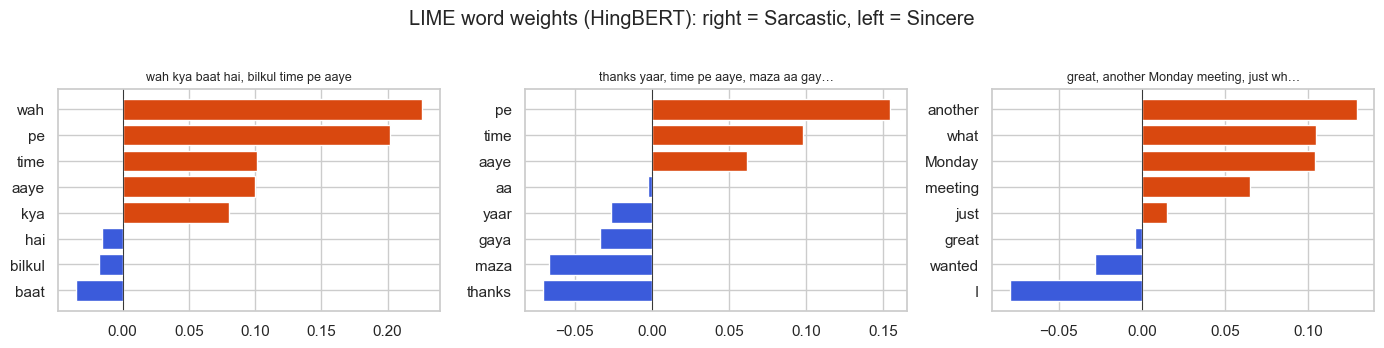

In [20]:
from src.predict import Predictor
from src.explain import explain

import joblib
if (MODELS / "hingbert" / "final").exists():
    hb, hb_name = Predictor("hingbert"), "HingBERT"
else:
    # model weights are not part of the Colab zip; explain the baseline instead
    MODELS.mkdir(exist_ok=True); joblib.dump(baseline, MODELS / "tfidf_lr.joblib")
    hb, hb_name = Predictor("tfidf_lr"), "TF-IDF + LR (HingBERT weights not available here)"
print("Explaining:", hb_name)
tests = ["wah kya baat hai, bilkul time pe aaye",
         "thanks yaar, time pe aaye, maza aa gaya",
         "great, another Monday meeting, just what I wanted"]
rows = [{"comment": t, **{k: v for k, v in hb.predict(t).items() if k != "probs"}} for t in tests]
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, t in zip(axes, tests):
    w = explain(hb, t, num_features=8, num_samples=400)
    w = sorted(w, key=lambda x: x[1])
    ax.barh([a for a, _ in w], [b for _, b in w], color=["#d9480f" if b > 0 else "#3b5bdb" for _, b in w])
    ax.set_title(t[:38] + ("…" if len(t) > 38 else ""), fontsize=9); ax.axvline(0, color="k", lw=.6)
fig.suptitle(f"LIME word weights ({hb_name}): right = Sarcastic, left = Sincere", y=1.02)
plt.tight_layout(); plt.show()

## 10. Conclusions and limitations

**Results (test set, 847 comments, macro-F1):** HingBERT is the best model; the TF-IDF baseline is surprisingly strong. See the table, chart and confidence intervals above for the exact numbers.

**Honest reading of the results**
- Our planned target of macro-F1 ≥ 0.80 was **not reached**.
- Only HingBERT clearly improves on the baseline, and the bootstrap shows the gain is modest. MuRIL and XLM-RoBERTa are statistically close to the baseline.
- Likely reasons: labels come from a single annotator and are noisy (sarcasm is subjective), comments are standalone with no conversation context, and spelling and code-mixing vary a lot.

**Limitations**
- We did not measure inter-annotator agreement (Cohen's kappa) ourselves; the dataset has one final label per comment.
- Results may not transfer to other platforms or topics; the data is mostly political and news-related social media comments.
- The dataset contains offensive language and its license is unspecified.
- Models were trained once with one hyperparameter setting; no tuning or repeated runs were done.

**Possible future work:** collect double-annotated data, add conversation context, tune hyperparameters, and ensemble TF-IDF with HingBERT.

**Reproduce:** `python -m src.prepare_data` → `python -m src.train_baseline` → `python -m src.finetune --model <muril|xlmr|hingbert>` (GPU) → run this notebook.